# 05. 2D Convolution, Max-Pooling, and Backpropagation from Scratch

**Task:** T5-017  
**Driver:** Sushil | **Navigator:** Yashwant  
**Concept Note:** [`docs/learning/convolution-pooling-and-backpropagation.md`](../docs/learning/convolution-pooling-and-backpropagation.md)  

---

## Executive Summary & Educational Focus

In precision agriculture and hydroponics, visual symptoms of nutrient deficiency (such as leaf chlorosis, necrosis, tip burn, and vascular fading) possess strong **spatial locality** and **translation equivariance**:
1. **Spatial Locality:** Defect patterns are formed by local clusters of neighboring pixels. A dense MLP flattening a 512x512 image requires over 260,000 weights per neuron and discards 2D spatial arrangement, while a 3x3 convolution requires only 9 weights per channel.
2. **Translation Equivariance:** A chlorotic lesion detected at the top-left of a leaf must be recognized with identical representation if it appears at the bottom-right.

This notebook builds the core mechanics of Convolutional Neural Networks (CNNs) from first principles:
- **NumPy 2D Convolution:** Sliding window cross-correlation with arbitrary channels, padding, and stride.
- **NumPy 2D Max-Pooling:** Downsampling and translation invariance.
- **Mathematical Equivalence Verification:** Exact assertion to machine tolerance ($< 10^{-6}$) against `torch.nn.functional.conv2d` and `torch.nn.functional.max_pool2d`.
- **Leaf Image Feature Extraction:** Applying classical Sobel horizontal, vertical, edge magnitude, and Laplacian filters to real hydroponic lettuce leaf images.
- **Feature Map Visualization:** Multi-panel visualization of spatial feature maps.
- **Autograd & Backpropagation Intuition:** Deriving and computing weight gradients $\frac{\partial L}{\partial W}$ in NumPy and proving exact equivalence with PyTorch Autograd.
- **Self-Check Questions:** Rigorous answers to conceptual interview questions.

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

print(f"NumPy version: {np.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"OpenCV version: {cv2.__version__}")
print(f"Project root: {PROJECT_ROOT}")

NumPy version: 2.5.3
PyTorch version: 2.7.1+cu118
OpenCV version: 4.13.0
Project root: D:\Hydroponic-Nutrition-AI


## 1. 2D Convolution from Scratch (Pure NumPy)

### Mathematical Cross-Correlation Formula
For input $X \in \mathbb{R}^{C_{\text{in}} \times H \times W}$, kernel $W \in \mathbb{R}^{C_{\text{out}} \times C_{\text{in}} \times K_h \times K_w}$, and bias $b \in \mathbb{R}^{C_{\text{out}}}$:

$$
Y[c_{\text{out}}, i, j] = b[c_{\text{out}}] + \sum_{c_{\text{in}}=0}^{C_{\text{in}}-1} \sum_{m=0}^{K_h-1} \sum_{n=0}^{K_w-1} X_{\text{pad}}[c_{\text{in}}, i \cdot S + m, j \cdot S + n] \cdot W[c_{\text{out}}, c_{\text{in}}, m, n]
$$

Output spatial dimensions:
$$
H_{\text{out}} = \left\lfloor \frac{H + 2P - K_h}{S} \right\rfloor + 1, \quad W_{\text{out}} = \left\lfloor \frac{W + 2P - K_w}{S} \right\rfloor + 1
$$

In [2]:
def conv2d_scratch(
    X: np.ndarray,
    W: np.ndarray,
    bias: np.ndarray | None = None,
    stride: int = 1,
    padding: int = 0,
) -> np.ndarray:
    """Compute 2D convolution (cross-correlation) from scratch in pure NumPy.

    Args:
        X: Input array of shape (C_in, H, W) or (N, C_in, H, W)
        W: Kernel weights of shape (C_out, C_in, Kh, Kw)
        bias: Optional bias vector of shape (C_out,)
        stride: Spatial stride step size
        padding: Zero padding width added to all 4 spatial borders

    Returns:
        Output feature map of shape (C_out, H_out, W_out) or (N, C_out, H_out, W_out)
    """
    is_batched = X.ndim == 4
    if not is_batched:
        # Add batch dimension: (1, C_in, H, W)
        X_batch = X[np.newaxis, ...]
    else:
        X_batch = X

    N, C_in, H, W_in = X_batch.shape
    C_out, C_in_k, Kh, Kw = W.shape
    assert C_in == C_in_k, f"Channel mismatch: X has {C_in} channels, W has {C_in_k}"

    # Zero padding on spatial dimensions
    if padding > 0:
        X_pad = np.pad(
            X_batch,
            ((0, 0), (0, 0), (padding, padding), (padding, padding)),
            mode="constant",
            constant_values=0,
        )
    else:
        X_pad = X_batch

    H_pad, W_pad = X_pad.shape[2], X_pad.shape[3]
    H_out = (H_pad - Kh) // stride + 1
    W_out = (W_pad - Kw) // stride + 1

    Y = np.zeros((N, C_out, H_out, W_out), dtype=np.float64)

    for n in range(N):
        for c_out in range(C_out):
            b_val = bias[c_out] if bias is not None else 0.0
            for i in range(H_out):
                for j in range(W_out):
                    h_start = i * stride
                    h_end = h_start + Kh
                    w_start = j * stride
                    w_end = w_start + Kw

                    receptive_field = X_pad[n, :, h_start:h_end, w_start:w_end]
                    val = np.sum(receptive_field * W[c_out]) + b_val
                    Y[n, c_out, i, j] = val

    return Y if is_batched else Y[0]

print("conv2d_scratch defined successfully.")

conv2d_scratch defined successfully.


## 2. Mathematical Verification against PyTorch `conv2d`

We verify that our NumPy implementation matches `torch.nn.functional.conv2d` to machine precision ($< 10^{-6}$) on a multi-channel example with padding and stride.

In [3]:
# Controlled synthetic test
np.random.seed(42)
X_toy = np.random.randn(2, 6, 6).astype(np.float64)  # C_in=2, H=6, W=6
W_toy = np.random.randn(3, 2, 3, 3).astype(np.float64)  # C_out=3, C_in=2, Kh=3, Kw=3
b_toy = np.random.randn(3).astype(np.float64)  # C_out=3

# Forward in NumPy
Y_numpy = conv2d_scratch(X_toy, W_toy, bias=b_toy, stride=1, padding=1)

# Forward in PyTorch
X_torch = torch.tensor(X_toy, dtype=torch.float64).unsqueeze(0)  # (1, 2, 6, 6)
W_torch = torch.tensor(W_toy, dtype=torch.float64)  # (3, 2, 3, 3)
b_torch = torch.tensor(b_toy, dtype=torch.float64)  # (3,)

Y_torch = F.conv2d(X_torch, W_torch, b_torch, stride=1, padding=1).squeeze(0).numpy()

# Exact comparison
max_diff = np.max(np.abs(Y_numpy - Y_torch))
print(f"Output shape: {Y_numpy.shape}")
print(f"Maximum absolute difference: {max_diff:.2e}")
np.testing.assert_allclose(Y_numpy, Y_torch, atol=1e-6)
print("[PASS] NumPy convolution matches torch.nn.functional.conv2d exactly!")

Output shape: (3, 6, 6)
Maximum absolute difference: 1.78e-15
[PASS] NumPy convolution matches torch.nn.functional.conv2d exactly!


## 3. 2D Max-Pooling from Scratch (Pure NumPy)

Max-pooling downsamples spatial dimensions by taking the maximum value in each window, conferring local translation invariance.

In [4]:
def max_pool2d_scratch(
    X: np.ndarray,
    pool_size: int = 2,
    stride: int = 2,
) -> np.ndarray:
    """Compute 2D max-pooling from scratch in pure NumPy.

    Args:
        X: Input array of shape (C, H, W) or (N, C, H, W)
        pool_size: Spatial pooling window dimension
        stride: Stride step size

    Returns:
        Max-pooled output array
    """
    is_batched = X.ndim == 4
    X_batch = X if is_batched else X[np.newaxis, ...]
    N, C, H, W = X_batch.shape

    H_out = (H - pool_size) // stride + 1
    W_out = (W - pool_size) // stride + 1

    Y = np.zeros((N, C, H_out, W_out), dtype=np.float64)

    for n in range(N):
        for c in range(C):
            for i in range(H_out):
                for j in range(W_out):
                    h_start = i * stride
                    h_end = h_start + pool_size
                    w_start = j * stride
                    w_end = w_start + pool_size
                    Y[n, c, i, j] = np.max(X_batch[n, c, h_start:h_end, w_start:w_end])

    return Y if is_batched else Y[0]

# Verify against PyTorch
pool_numpy = max_pool2d_scratch(X_toy, pool_size=2, stride=2)
pool_torch = F.max_pool2d(X_torch, kernel_size=2, stride=2).squeeze(0).numpy()

max_pool_diff = np.max(np.abs(pool_numpy - pool_torch))
print(f"Max pool shape: {pool_numpy.shape}")
print(f"Max pool difference: {max_pool_diff:.2e}")
np.testing.assert_allclose(pool_numpy, pool_torch, atol=1e-6)
print("[PASS] NumPy max-pooling matches torch.nn.functional.max_pool2d exactly!")

Max pool shape: (2, 3, 3)
Max pool difference: 0.00e+00
[PASS] NumPy max-pooling matches torch.nn.functional.max_pool2d exactly!


## 4. Applying Edge Filters to a Real Hydroponic Leaf Image

Classical edge detection filters (Sobel horizontal $G_x$, Sobel vertical $G_y$, and isotropic Laplacian) are fixed $3 \times 3$ kernels that compute image derivatives to reveal leaf veins, margins, and necrotic lesion boundaries:

- **Sobel Horizontal ($G_x$):** Detects vertical intensity transitions (vein columns):
  $$
  G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}
  $$
- **Sobel Vertical ($G_y$):** Detects horizontal intensity transitions (vein rows):
  $$
  G_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}
  $$
- **Gradient Magnitude:** $G = \sqrt{G_x^2 + G_y^2}$
- **Laplacian:** Second-order derivative highlighting rapid edge inflections:
  $$
  \nabla^2 = \begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}
  $$

In [5]:
# Load real hydroponic lettuce leaf image
leaf_path = PROJECT_ROOT / "image_data" / "Lettuce_Images" / "Healthier" / "Healthier_0001.jpg"
leaf_bgr = cv2.imread(str(leaf_path))
assert leaf_bgr is not None, f"Could not load image: {leaf_path}"

# Convert to RGB and grayscale in [0.0, 1.0]
leaf_rgb = cv2.cvtColor(leaf_bgr, cv2.COLOR_BGR2RGB)
leaf_gray = cv2.cvtColor(leaf_rgb, cv2.COLOR_RGB2GRAY).astype(np.float64) / 255.0

# Resize for crisp demonstration if large
leaf_gray_resized = cv2.resize(leaf_gray, (256, 256))
X_leaf = leaf_gray_resized[np.newaxis, ...]  # Shape: (1, 256, 256)

# Define Kernels
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64).reshape(1, 1, 3, 3)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64).reshape(1, 1, 3, 3)

laplacian = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float64).reshape(1, 1, 3, 3)

# Compute Feature Maps using NumPy from-scratch convolution
feat_sobel_x = conv2d_scratch(X_leaf, sobel_x, padding=1)[0]
feat_sobel_y = conv2d_scratch(X_leaf, sobel_y, padding=1)[0]
feat_magnitude = np.sqrt(feat_sobel_x**2 + feat_sobel_y**2)
feat_laplacian = np.abs(conv2d_scratch(X_leaf, laplacian, padding=1)[0])
feat_pooled = max_pool2d_scratch(feat_magnitude[np.newaxis, ...], pool_size=2, stride=2)[0]

print(f"Original leaf shape: {X_leaf.shape[1:]}")
print(f"Sobel feature map shape: {feat_magnitude.shape}")
print(f"Max-pooled feature map shape: {feat_pooled.shape}")

Original leaf shape: (256, 256)
Sobel feature map shape: (256, 256)
Max-pooled feature map shape: (128, 128)


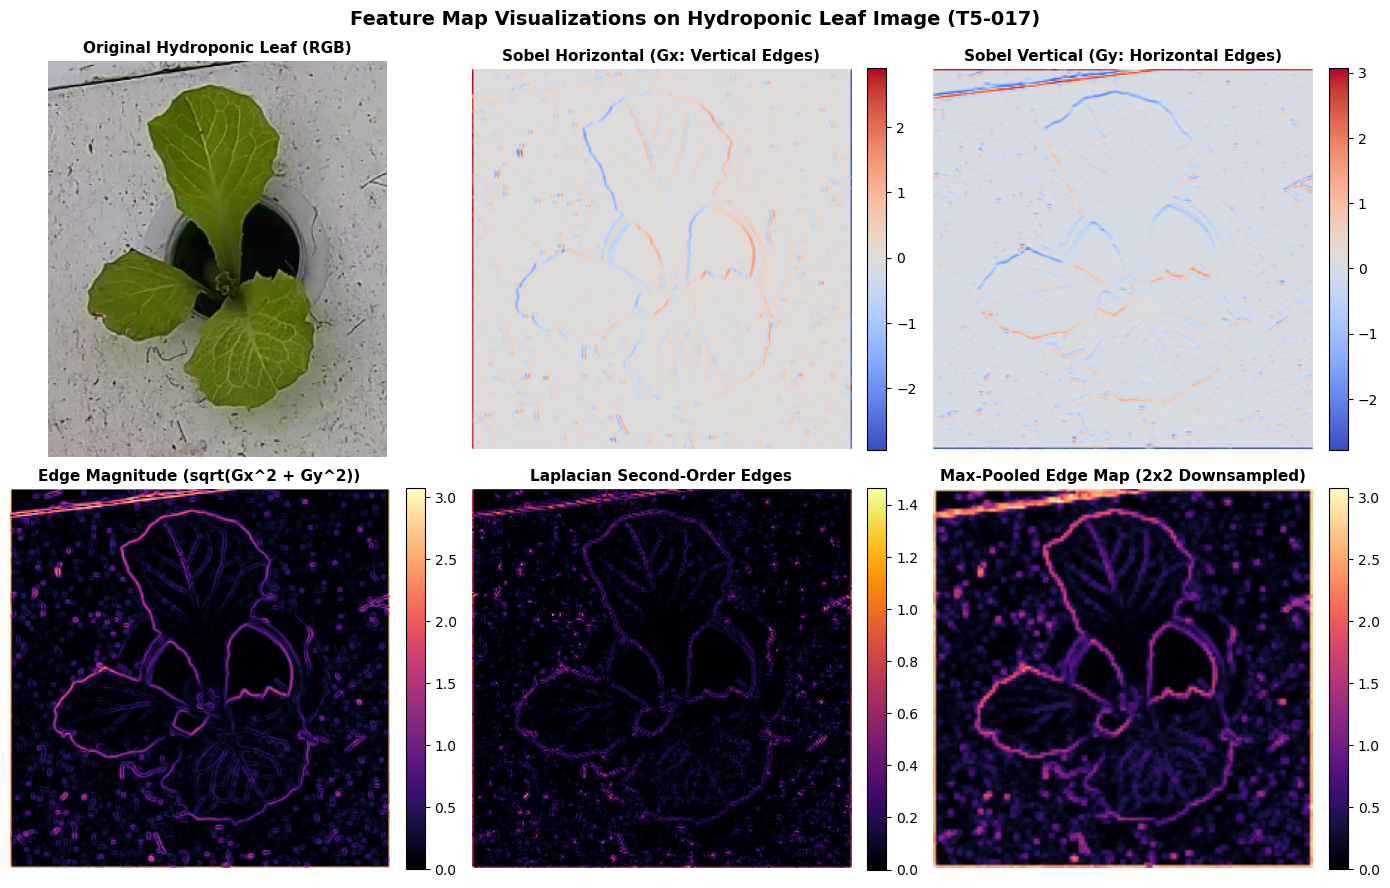

In [6]:
# Visualise Feature Maps (Acceptance Criterion 2)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(leaf_rgb)
axes[0, 0].set_title("Original Hydroponic Leaf (RGB)", fontsize=11, fontweight="bold")
axes[0, 0].axis("off")

im1 = axes[0, 1].imshow(feat_sobel_x, cmap="coolwarm")
axes[0, 1].set_title("Sobel Horizontal (Gx: Vertical Edges)", fontsize=11, fontweight="bold")
axes[0, 1].axis("off")
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

im2 = axes[0, 2].imshow(feat_sobel_y, cmap="coolwarm")
axes[0, 2].set_title("Sobel Vertical (Gy: Horizontal Edges)", fontsize=11, fontweight="bold")
axes[0, 2].axis("off")
plt.colorbar(im2, ax=axes[0, 2], fraction=0.046, pad=0.04)

im3 = axes[1, 0].imshow(feat_magnitude, cmap="magma")
axes[1, 0].set_title("Edge Magnitude (sqrt(Gx^2 + Gy^2))", fontsize=11, fontweight="bold")
axes[1, 0].axis("off")
plt.colorbar(im3, ax=axes[1, 0], fraction=0.046, pad=0.04)

im4 = axes[1, 1].imshow(feat_laplacian, cmap="inferno")
axes[1, 1].set_title("Laplacian Second-Order Edges", fontsize=11, fontweight="bold")
axes[1, 1].axis("off")
plt.colorbar(im4, ax=axes[1, 1], fraction=0.046, pad=0.04)

im5 = axes[1, 2].imshow(feat_pooled, cmap="magma")
axes[1, 2].set_title("Max-Pooled Edge Map (2x2 Downsampled)", fontsize=11, fontweight="bold")
axes[1, 2].axis("off")
plt.colorbar(im5, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.suptitle("Feature Map Visualizations on Hydroponic Leaf Image (T5-017)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

## 5. Autograd & Backpropagation Intuition: Weight Gradient as Convolution

### Mathematical Formulation
Given scalar loss $L = \frac{1}{2} \sum (Y - Y_{\text{target}})^2$, the upstream output gradient is $\delta = \frac{\partial L}{\partial Y} = Y - Y_{\text{target}}$.

The gradient with respect to filter weight $W[c_{\text{out}}, c_{\text{in}}, m, n]$ is:
$$
\frac{\partial L}{\partial W[c_{\text{out}}, c_{\text{in}}, m, n]} = \sum_{i=0}^{H_{\text{out}}-1} \sum_{j=0}^{W_{\text{out}}-1} \delta[c_{\text{out}}, i, j] \cdot X_{\text{pad}}[c_{\text{in}}, i \cdot S + m, j \cdot S + n]
$$

This demonstrates that **the backward pass to compute weight gradients is itself a 2D convolution** between the input feature map and the incoming gradient map!

In [7]:
# Backpropagation from scratch in NumPy
def conv2d_backward_weights_scratch(
    X: np.ndarray,
    dY: np.ndarray,
    kernel_shape: tuple,
    stride: int = 1,
    padding: int = 0,
) -> np.ndarray:
    """Compute dL/dW analytically from scratch using the convolution chain rule."""
    C_in, H, W_in = X.shape
    C_out, C_in_k, Kh, Kw = kernel_shape
    H_out, W_out = dY.shape[1], dY.shape[2]

    if padding > 0:
        X_pad = np.pad(X, ((0, 0), (padding, padding), (padding, padding)), mode="constant")
    else:
        X_pad = X

    dW = np.zeros(kernel_shape, dtype=np.float64)

    for c_out in range(C_out):
        for c_in in range(C_in):
            for m in range(Kh):
                for n in range(Kw):
                    # Slide over all spatial positions of the output gradient
                    grad_accum = 0.0
                    for i in range(H_out):
                        for j in range(W_out):
                            grad_accum += dY[c_out, i, j] * X_pad[c_in, i * stride + m, j * stride + n]
                    dW[c_out, c_in, m, n] = grad_accum

    return dW

# Run PyTorch Autograd comparison
torch.manual_seed(42)
X_grad_np = np.random.randn(1, 4, 4).astype(np.float64)
W_grad_np = np.random.randn(2, 1, 3, 3).astype(np.float64)
target_np = np.random.randn(2, 4, 4).astype(np.float64)

# PyTorch autograd
x_t = torch.tensor(X_grad_np, dtype=torch.float64).unsqueeze(0)  # (1, 1, 4, 4)
w_t = torch.tensor(W_grad_np, dtype=torch.float64, requires_grad=True)  # (2, 1, 3, 3)
target_t = torch.tensor(target_np, dtype=torch.float64).unsqueeze(0)

y_pred_t = F.conv2d(x_t, w_t, padding=1)
loss = 0.5 * torch.sum((y_pred_t - target_t) ** 2)
loss.backward()
torch_dW = w_t.grad.numpy()

# NumPy analytical gradient
y_pred_np = conv2d_scratch(X_grad_np, W_grad_np, padding=1)
dY_np = y_pred_np - target_np
numpy_dW = conv2d_backward_weights_scratch(X_grad_np, dY_np, W_grad_np.shape, padding=1)

max_grad_diff = np.max(np.abs(numpy_dW - torch_dW))
print(f"Maximum gradient difference dL/dW: {max_grad_diff:.2e}")
np.testing.assert_allclose(numpy_dW, torch_dW, atol=1e-6)
print("[PASS] NumPy analytical weight gradient matches PyTorch Autograd exactly!")

Maximum gradient difference dL/dW: 3.55e-15
[PASS] NumPy analytical weight gradient matches PyTorch Autograd exactly!


## 6. Self-Check Questions and Answers (Acceptance Criterion 3)

### Q1: Why is the operation called "convolution" in PyTorch actually cross-correlation, and why does this distinction not matter for deep learning?
**Answer:** True mathematical convolution requires flipping the kernel along both spatial axes ($\tilde{W}[m, n] = W[-m, -n]$) before computing the inner product to satisfy algebraic commutativity ($f * g = g * f$). Cross-correlation slides the kernel without flipping. In deep learning, commutativity is not required. Because convolutional filters are initialized randomly and learned entirely via backpropagation, the optimizer simply learns the un-flipped weights directly. Performing the spatial flip would add unnecessary computation without changing representation capacity.

### Q2: Given an input tensor of size $3 \times 224 \times 224$, a convolutional layer with 64 filters of size $7 \times 7$, stride 2, and padding 3, what are the output spatial dimensions and the total number of learnable parameters (including bias)?
**Answer:**
- Output spatial dimensions:
  $$ H_{\text{out}} = \left\lfloor \frac{224 + 2(3) - 7}{2} \right\rfloor + 1 = \left\lfloor \frac{223}{2} \right\rfloor + 1 = 111 + 1 = 112 $$
  The output tensor has shape $(64, 112, 112)$.
- Total learnable parameters:
  $$ \text{Weights} = C_{\text{out}} \times C_{\text{in}} \times K_h \times K_w = 64 \times 3 \times 7 \times 7 = 9,408 $$
  $$ \text{Biases} = C_{\text{out}} = 64 $$
  $$ \text{Total} = 9,408 + 64 = 9,472 \text{ parameters}. $$

### Q3: What mathematical operation computes the gradient of the loss with respect to filter weights during backpropagation?
**Answer:** The gradient with respect to filter weights $\frac{\partial L}{\partial W}$ is mathematically a **cross-correlation / convolution between the input activations $X$ and the upstream output gradient $\frac{\partial L}{\partial Y}$**. Each filter weight element accumulates the sum of products of input receptive field pixels with the corresponding output gradient error over all sliding window positions.

### Q4: How does backpropagation work through a 2D max-pooling layer?
**Answer:** Max-pooling acts as a **dynamic routing switch**. During the forward pass, the coordinate index of the maximum value within each pooling window is recorded (the argmax mask). During the backward pass, the upstream gradient $\delta_{\text{out}}$ is routed exclusively to the single input position that achieved the maximum; all other elements in that pooling window receive a gradient of 0.

### Q5: How do classical edge filters (Sobel, Laplacian) relate to early layers of trained deep convolutional neural networks?
**Answer:** Classical filters like Sobel and Laplacian are handcrafted, fixed approximations of first-order and second-order derivatives designed to detect intensity discontinuities (edges, ridges). When deep CNNs (such as ResNet or MobileNet) are trained via backpropagation on natural or agricultural images, the first-layer convolutional filters **empirically converge to oriented Gabor-like edge detectors, color-opponent filters, and center-surround blobs**, naturally rediscovering classical spatial filters without human intervention.